In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    roc_auc_score
)

print("TensorFlow version:", tf.__version__)
print("NumPy version:", np.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
NumPy version: 2.5.4
GPU available: []


In [2]:
# Load AWGN raw IQ dataset
data = np.load("spectrum_sensing_dataset.npz")

X_iq = data["X"]
y = data["y"]
snr = data["snr"]

print("IQ dataset shape:", X_iq.shape)
print("Labels shape:", y.shape)
print("SNR shape:", snr.shape)

print("\nClass distribution:")
print(pd.Series(y).value_counts().sort_index())

print("\nData type:", X_iq.dtype)
print("Window length:", X_iq.shape[1])

IQ dataset shape: (14000, 256)
Labels shape: (14000,)
SNR shape: (14000,)

Class distribution:
0    7000
1    7000
Name: count, dtype: int64

Data type: complex128
Window length: 256


In [3]:
# Separate real and imaginary components
X_I = X_iq.real
X_Q = X_iq.imag

# Stack I and Q as separate channels
X_cnn = np.stack(
    [X_I, X_Q],
    axis=-1
).astype(np.float32)

# Convert labels to float32
y_cnn = y.astype(np.float32)

print("CNN input shape:", X_cnn.shape)
print("CNN label shape:", y_cnn.shape)

print("Data type:", X_cnn.dtype)
print("I channel shape:", X_cnn[:, :, 0].shape)
print("Q channel shape:", X_cnn[:, :, 1].shape)

print("\nFirst sample:")
print(X_cnn[0, :5, :])

CNN input shape: (14000, 256, 2)
CNN label shape: (14000,)
Data type: float32
I channel shape: (14000, 256)
Q channel shape: (14000, 256)

First sample:
[[ 0.41186085  1.1248906 ]
 [-5.942516    4.788063  ]
 [-4.313511   13.634719  ]
 [ 0.83966875  1.9807878 ]
 [-8.938633   -6.6437216 ]]


In [4]:
from sklearn.model_selection import train_test_split

# Combine occupancy label and SNR for stratification
groups = np.array([
    f"{label}_{snr_value}"
    for label, snr_value in zip(y, snr)
])

indices = np.arange(len(y_cnn))

# First split: 70% training, 30% temporary
train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.30,
    random_state=42,
    stratify=groups
)

# Second split: 15% validation, 15% testing
temp_groups = groups[temp_idx]

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=42,
    stratify=temp_groups
)

# Create datasets
X_train = X_cnn[train_idx]
X_val = X_cnn[val_idx]
X_test = X_cnn[test_idx]

y_train = y_cnn[train_idx]
y_val = y_cnn[val_idx]
y_test = y_cnn[test_idx]

print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Testing shape:", X_test.shape)

print("\nTraining labels:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nValidation labels:")
print(pd.Series(y_val).value_counts().sort_index())

print("\nTesting labels:")
print(pd.Series(y_test).value_counts().sort_index())

Training shape: (9800, 256, 2)
Validation shape: (2100, 256, 2)
Testing shape: (2100, 256, 2)

Training labels:
0.0    4900
1.0    4900
Name: count, dtype: int64

Validation labels:
0.0    1050
1.0    1050
Name: count, dtype: int64

Testing labels:
0.0    1050
1.0    1050
Name: count, dtype: int64


In [5]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv1D,
    MaxPooling1D,
    GlobalAveragePooling1D,
    Dense,
    Dropout
)

from tensorflow.keras.optimizers import Adam

# Build 1D-CNN
cnn_model = Sequential([
    Input(shape=(256, 2)),

    Conv1D(
        filters=32,
        kernel_size=5,
        activation="relu",
        padding="same"
    ),

    MaxPooling1D(pool_size=2),

    Conv1D(
        filters=64,
        kernel_size=3,
        activation="relu",
        padding="same"
    ),

    GlobalAveragePooling1D(),

    Dense(64, activation="relu"),

    Dropout(0.3),

    Dense(1, activation="sigmoid")
])

# Compile model
cnn_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Display architecture
cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 256, 32)        │           352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 128, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 128, 64)        │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,785 (42.13 KB)

 Trainable params: 10,785 (42.13 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

history = cnn_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/30
154/154 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.5406 - loss: 0.6874 - val_accuracy: 0.5795 - val_loss: 0.6425
Epoch 2/30
154/154 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.6623 - loss: 0.5852 - val_accuracy: 0.6867 - val_loss: 0.5453
Epoch 3/30
154/154 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.6841 - loss: 0.5351 - val_accuracy: 0.7052 - val_loss: 0.5136
Epoch 4/30
154/154 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.6964 - loss: 0.5045 - val_accuracy: 0.7114 - val_loss: 0.4779
Epoch 5/30
154/154 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7036 - loss: 0.4734 - val_accuracy: 0.7114 - val_loss: 0.4506
Epoch 6/30
154/154 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7046 - loss: 0.4514 - val_accuracy: 0.7090 - val_loss: 0.4371
Epoch 7/30
154/154 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7068 - loss: 0.4421 - val_accuracy: 0.7100 - val_loss: 0.4264
Epoch 8/30
154/154 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7092 - loss: 0.4302 - val_accuracy: 0.

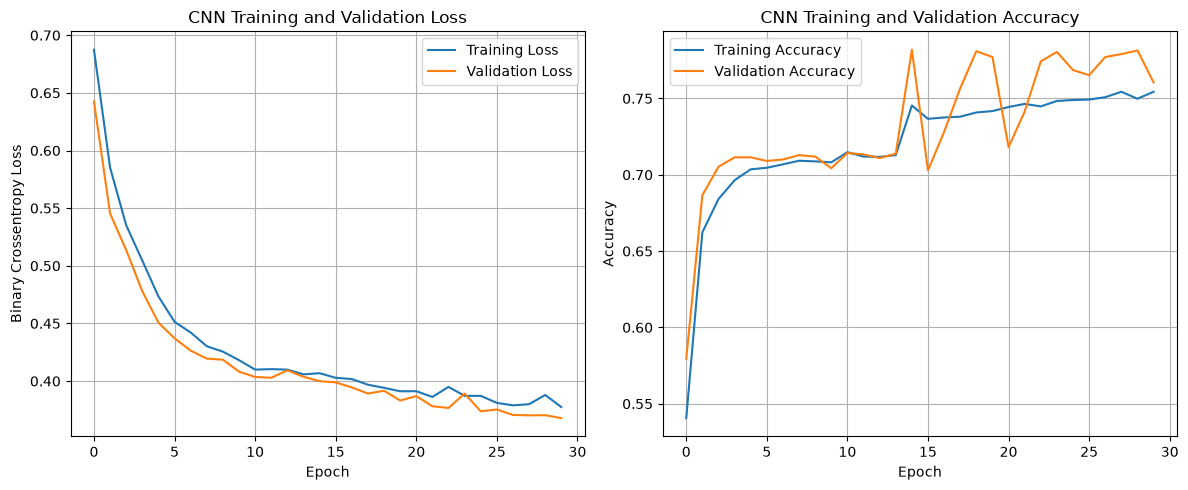

In [7]:
plt.figure(figsize=(12, 5))

# Loss plot
plt.subplot(1, 2, 1)

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("CNN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Crossentropy Loss")
plt.legend()
plt.grid(True)

# Accuracy plot
plt.subplot(1, 2, 2)

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("CNN Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig("cnn_training_curves.png", dpi=300)
plt.show()

In [8]:
# Predict probabilities on validation data
cnn_val_prob = cnn_model.predict(X_val).ravel()

# Extract H0 validation probabilities
cnn_val_h0_prob = cnn_val_prob[y_val == 0]

# Calibrate threshold for approximately 5% Pfa
cnn_threshold = np.quantile(
    cnn_val_h0_prob,
    0.95,
    method="higher"
)

# Calculate validation predictions
cnn_val_pred = (cnn_val_prob > cnn_threshold).astype(int)

# Calculate validation metrics
tn, fp, fn, tp = confusion_matrix(
    y_val.astype(int),
    cnn_val_pred,
    labels=[0, 1]
).ravel()

val_accuracy = accuracy_score(
    y_val.astype(int),
    cnn_val_pred
)

val_pd = tp / (tp + fn)
val_pfa = fp / (fp + tn)
val_pm = fn / (fn + tp)

print("CNN Threshold:", cnn_threshold)

print("\nValidation Results:")
print("Accuracy:", val_accuracy)
print("Pd:", val_pd)
print("Pfa:", val_pfa)
print("Pm:", val_pm)

66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
CNN Threshold: 0.533056

Validation Results:
Accuracy: 0.7138095238095238
Pd: 0.42857142857142855
Pfa: 0.0009523809523809524
Pm: 0.5714285714285714


In [9]:
# Inspect H0 validation probability distribution

print("Total H0 validation samples:", len(cnn_val_h0_prob))

print("Below threshold:",
      np.sum(cnn_val_h0_prob < cnn_threshold))

print("Equal to threshold:",
      np.sum(cnn_val_h0_prob == cnn_threshold))

print("Above threshold:",
      np.sum(cnn_val_h0_prob > cnn_threshold))

print("\nUnique H0 probabilities:",
      len(np.unique(cnn_val_h0_prob)))

print("\n95th percentile:",
      np.quantile(cnn_val_h0_prob, 0.95))

print("\nMinimum probability:", np.min(cnn_val_h0_prob))
print("Maximum probability:", np.max(cnn_val_h0_prob))

Total H0 validation samples: 1050
Below threshold: 599
Equal to threshold: 450
Above threshold: 1

Unique H0 probabilities: 302

95th percentile: 0.533056

Minimum probability: 0.0
Maximum probability: 0.57209074


In [10]:
# Calculate global channel-wise statistics from training data only

channel_mean = np.mean(
    X_train,
    axis=(0, 1),
    keepdims=True
)

channel_std = np.std(
    X_train,
    axis=(0, 1),
    keepdims=True
)

# Avoid division by zero
channel_std = np.maximum(channel_std, 1e-8)

# Standardize all datasets using training statistics
X_train_scaled = (
    X_train - channel_mean
) / channel_std

X_val_scaled = (
    X_val - channel_mean
) / channel_std

X_test_scaled = (
    X_test - channel_mean
) / channel_std

print("Channel means:", channel_mean.ravel())
print("Channel standard deviations:", channel_std.ravel())

print("\nScaled training shape:", X_train_scaled.shape)
print("Scaled validation shape:", X_val_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)

print("\nTraining channel means:",
      X_train_scaled.mean(axis=(0, 1)))

print("Training channel standard deviations:",
      X_train_scaled.std(axis=(0, 1)))

Channel means: [ 0.00065152 -0.00108236]
Channel standard deviations: [3.2636547 3.2630541]

Scaled training shape: (9800, 256, 2)
Scaled validation shape: (2100, 256, 2)
Scaled testing shape: (2100, 256, 2)

Training channel means: [-2.4836401e-08  5.9600489e-09]
Training channel standard deviations: [1.000011  0.9999867]


In [11]:
# Create a fresh CNN
cnn_model_scaled = Sequential([
    Input(shape=(256, 2)),

    Conv1D(32, 5, activation="relu", padding="same"),
    MaxPooling1D(pool_size=2),

    Conv1D(64, 3, activation="relu", padding="same"),

    GlobalAveragePooling1D(),

    Dense(64, activation="relu"),
    Dropout(0.3),

    Dense(1, activation="sigmoid")
])

# Compile
cnn_model_scaled.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Early stopping
early_stopping_scaled = EarlyStopping(
    monitor="val_loss",
    patience=7,
    restore_best_weights=True,
    verbose=1
)

# Train
history_scaled = cnn_model_scaled.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=40,
    batch_size=64,
    callbacks=[early_stopping_scaled],
    verbose=1
)

Epoch 1/40
154/154 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.5796 - loss: 0.6650 - val_accuracy: 0.6700 - val_loss: 0.5974
Epoch 2/40
154/154 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6917 - loss: 0.5575 - val_accuracy: 0.6724 - val_loss: 0.5364
Epoch 3/40
154/154 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6959 - loss: 0.5176 - val_accuracy: 0.7133 - val_loss: 0.4983
Epoch 4/40
154/154 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7027 - loss: 0.4838 - val_accuracy: 0.7133 - val_loss: 0.4600
Epoch 5/40
154/154 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7061 - loss: 0.4565 - val_accuracy: 0.7114 - val_loss: 0.4406
Epoch 6/40
154/154 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7094 - loss: 0.4411 - val_accuracy: 0.7110 - val_loss: 0.4280
Epoch 7/40
154/154 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7088 - loss: 0.4290 - val_accuracy: 0.6976 - val_loss: 0.4194
Epoch 8/40
154/154 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7126 - loss: 0.4204 - val_accuracy: 0.

In [12]:
# Predict validation probabilities
cnn_val_prob = cnn_model_scaled.predict(
    X_val_scaled
).ravel()

# H0 probabilities only
cnn_val_h0_prob = cnn_val_prob[y_val == 0]

# Calibrate threshold
cnn_threshold = np.quantile(
    cnn_val_h0_prob,
    0.95,
    method="higher"
)

# Calculate validation predictions
cnn_val_pred = (
    cnn_val_prob > cnn_threshold
).astype(int)

# Calculate confusion matrix
tn, fp, fn, tp = confusion_matrix(
    y_val.astype(int),
    cnn_val_pred,
    labels=[0, 1]
).ravel()

print("Threshold:", cnn_threshold)
print("H0 probabilities:", len(cnn_val_h0_prob))
print("Unique H0 probabilities:", len(np.unique(cnn_val_h0_prob)))
print("Equal to threshold:",
      np.sum(cnn_val_h0_prob == cnn_threshold))

print("\nValidation metrics:")
print("Accuracy:", accuracy_score(y_val, cnn_val_pred))
print("Pd:", tp / (tp + fn))
print("Pfa:", fp / (fp + tn))
print("Pm:", fn / (fn + tp))

66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
Threshold: 0.51372516
H0 probabilities: 1050
Unique H0 probabilities: 744
Equal to threshold: 1

Validation metrics:
Accuracy: 0.7619047619047619
Pd: 0.5733333333333334
Pfa: 0.049523809523809526
Pm: 0.4266666666666667


In [13]:
# Predict test probabilities
cnn_test_prob = cnn_model_scaled.predict(
    X_test_scaled
).ravel()

# Apply validation-calibrated threshold
cnn_test_pred = (
    cnn_test_prob > cnn_threshold
).astype(int)

# Calculate confusion matrix
tn, fp, fn, tp = confusion_matrix(
    y_test.astype(int),
    cnn_test_pred,
    labels=[0, 1]
).ravel()

# Calculate performance metrics
cnn_test_accuracy = accuracy_score(
    y_test.astype(int),
    cnn_test_pred
)

cnn_test_pd = tp / (tp + fn)
cnn_test_pfa = fp / (fp + tn)
cnn_test_pm = fn / (fn + tp)

cnn_test_auc = roc_auc_score(
    y_test,
    cnn_test_prob
)

print("CNN TEST RESULTS")
print("---------------------------")
print("Threshold:", cnn_threshold)
print("Accuracy:", cnn_test_accuracy)
print("Detection Probability (Pd):", cnn_test_pd)
print("False Alarm Probability (Pfa):", cnn_test_pfa)
print("Miss Probability (Pm):", cnn_test_pm)
print("ROC-AUC:", cnn_test_auc)

print("\nConfusion Matrix:")
print(np.array([[tn, fp], [fn, tp]]))

66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
CNN TEST RESULTS
---------------------------
Threshold: 0.51372516
Accuracy: 0.7685714285714286
Detection Probability (Pd): 0.5733333333333334
False Alarm Probability (Pfa): 0.03619047619047619
Miss Probability (Pm): 0.4266666666666667
ROC-AUC: 0.8969410430839002

Confusion Matrix:
[[1012   38]
 [ 448  602]]


In [15]:
# Load engineered AWGN features
feature_data = np.load("spectrum_sensing_features.npz")

X_features = feature_data["X"]
feature_names = feature_data["feature_names"]

print("Feature matrix shape:", X_features.shape)
print("Feature count:", len(feature_names))
print("CNN training indices:", len(train_idx))
print("CNN validation indices:", len(val_idx))
print("CNN testing indices:", len(test_idx))

Feature matrix shape: (14000, 13)
Feature count: 13
CNN training indices: 9800
CNN validation indices: 2100
CNN testing indices: 2100


In [16]:
# Logistic Regression: same seed-42 split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Logistic Regression
lr_scaler = StandardScaler()

X_lr_train = lr_scaler.fit_transform(X_features[train_idx])
X_lr_val = lr_scaler.transform(X_features[val_idx])
X_lr_test = lr_scaler.transform(X_features[test_idx])

lr_model_comparison = LogisticRegression(
    max_iter=1000,
    random_state=42,
    class_weight="balanced"
)

lr_model_comparison.fit(X_lr_train, y_train.astype(int))

lr_val_prob = lr_model_comparison.predict_proba(X_lr_val)[:, 1]
lr_test_prob = lr_model_comparison.predict_proba(X_lr_test)[:, 1]

lr_threshold_comparison = np.quantile(
    lr_val_prob[y_val == 0],
    0.95,
    method="higher"
)

# Random Forest
rf_model_comparison = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

rf_model_comparison.fit(
    X_features[train_idx],
    y_train.astype(int)
)

rf_val_prob = rf_model_comparison.predict_proba(
    X_features[val_idx]
)[:, 1]

rf_test_prob = rf_model_comparison.predict_proba(
    X_features[test_idx]
)[:, 1]

rf_threshold_comparison = np.quantile(
    rf_val_prob[y_val == 0],
    0.95,
    method="higher"
)

print("Logistic Regression threshold:", lr_threshold_comparison)
print("Random Forest threshold:", rf_threshold_comparison)
print("CNN threshold:", cnn_threshold)

Logistic Regression threshold: 0.7525429211626531
Random Forest threshold: 0.62
CNN threshold: 0.51372516


In [17]:
# Store model probabilities and thresholds
model_predictions = {
    "Logistic Regression": (lr_test_prob, lr_threshold_comparison),
    "Random Forest": (rf_test_prob, rf_threshold_comparison),
    "1D-CNN": (cnn_test_prob, cnn_threshold)
}

comparison_results = []

for model_name, (probabilities, threshold) in model_predictions.items():

    predictions = (probabilities > threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test.astype(int),
        predictions,
        labels=[0, 1]
    ).ravel()

    comparison_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Pd": tp / (tp + fn),
        "Pfa": fp / (fp + tn),
        "Pm": fn / (fn + tp),
        "ROC_AUC": roc_auc_score(y_test, probabilities),
        "Threshold": threshold
    })

comparison_df = pd.DataFrame(comparison_results)

print("FINAL AWGN MODEL COMPARISON")
print(comparison_df.round(4).to_string(index=False))

FINAL AWGN MODEL COMPARISON
              Model  Accuracy     Pd    Pfa     Pm  ROC_AUC  Threshold
Logistic Regression    0.6719 0.3838 0.0400 0.6162   0.8314     0.7525
      Random Forest    0.8219 0.6990 0.0552 0.3010   0.9383     0.6200
             1D-CNN    0.7686 0.5733 0.0362 0.4267   0.8969     0.5137


In [18]:
comparison_df.to_csv(
    "awgn_three_model_comparison.csv",
    index=False
)

print("AWGN comparison saved successfully.")

AWGN comparison saved successfully.


In [19]:
# Load Rayleigh fading dataset
rayleigh_data = np.load("rayleigh_fading_dataset.npz")

X_rayleigh = rayleigh_data["X"]
y_rayleigh = rayleigh_data["y"]
snr_rayleigh = rayleigh_data["snr"]

print("Rayleigh raw data shape:", X_rayleigh.shape)
print("Rayleigh labels shape:", y_rayleigh.shape)
print("Rayleigh SNR shape:", snr_rayleigh.shape)

print("\nClass distribution:")
print("H0 (noise only):", np.sum(y_rayleigh == 0))
print("H1 (signal present):", np.sum(y_rayleigh == 1))

print("\nSNR values:", np.unique(snr_rayleigh))

Rayleigh raw data shape: (14000, 256)
Rayleigh labels shape: (14000,)
Rayleigh SNR shape: (14000,)

Class distribution:
H0 (noise only): 7000
H1 (signal present): 7000

SNR values: [-20 -15 -10  -5   0   5  10]


In [20]:
# Verify AWGN and Rayleigh dataset alignment

awgn_data = np.load("spectrum_sensing_dataset.npz")

y_awgn = awgn_data["y"]
snr_awgn = awgn_data["snr"]

print("Labels match:", np.array_equal(y_awgn, y_rayleigh))
print("SNR ordering matches:", np.array_equal(snr_awgn, snr_rayleigh))

# Verify the existing test indices
print("\nTest samples:", len(test_idx))
print("Test H0 samples:", np.sum(y_rayleigh[test_idx] == 0))
print("Test H1 samples:", np.sum(y_rayleigh[test_idx] == 1))

Labels match: True
SNR ordering matches: True

Test samples: 2100
Test H0 samples: 1050
Test H1 samples: 1050


In [21]:
# Convert complex Rayleigh samples into I/Q channels
X_rayleigh_cnn = np.stack(
    [X_rayleigh.real, X_rayleigh.imag],
    axis=-1
).astype(np.float32)

# Apply the original AWGN training-set normalization
X_rayleigh_scaled = (
    X_rayleigh_cnn - channel_mean
) / channel_std

# Select the existing test observations
X_rayleigh_test = X_rayleigh_scaled[test_idx]
y_rayleigh_test = y_rayleigh[test_idx]

print("Rayleigh CNN data shape:", X_rayleigh_cnn.shape)
print("Scaled Rayleigh data shape:", X_rayleigh_scaled.shape)
print("Rayleigh test shape:", X_rayleigh_test.shape)
print("Test labels shape:", y_rayleigh_test.shape)

print("\nScaled test channel means:")
print(np.mean(X_rayleigh_test, axis=(0, 1)))

print("\nScaled test channel standard deviations:")
print(np.std(X_rayleigh_test, axis=(0, 1)))

Rayleigh CNN data shape: (14000, 256, 2)
Scaled Rayleigh data shape: (14000, 256, 2)
Rayleigh test shape: (2100, 256, 2)
Test labels shape: (2100,)

Scaled test channel means:
[-0.00013234 -0.00057418]

Scaled test channel standard deviations:
[1.0009873 1.0085415]


In [22]:
# Predict Rayleigh test samples using AWGN-trained CNN
rayleigh_cnn_prob = cnn_model_scaled.predict(
    X_rayleigh_test
).ravel()

# Apply the original AWGN validation threshold
rayleigh_cnn_pred = (
    rayleigh_cnn_prob > cnn_threshold
).astype(int)

# Calculate confusion matrix
tn, fp, fn, tp = confusion_matrix(
    y_rayleigh_test,
    rayleigh_cnn_pred,
    labels=[0, 1]
).ravel()

# Calculate evaluation metrics
rayleigh_cnn_accuracy = accuracy_score(
    y_rayleigh_test,
    rayleigh_cnn_pred
)

rayleigh_cnn_pd = tp / (tp + fn)
rayleigh_cnn_pfa = fp / (fp + tn)
rayleigh_cnn_pm = fn / (fn + tp)

rayleigh_cnn_auc = roc_auc_score(
    y_rayleigh_test,
    rayleigh_cnn_prob
)

print("AWGN-TRAINED CNN ON RAYLEIGH TEST DATA")
print("--------------------------------------")
print("Threshold:", cnn_threshold)
print("Accuracy:", round(rayleigh_cnn_accuracy, 4))
print("Pd:", round(rayleigh_cnn_pd, 4))
print("Pfa:", round(rayleigh_cnn_pfa, 4))
print("Pm:", round(rayleigh_cnn_pm, 4))
print("ROC-AUC:", round(rayleigh_cnn_auc, 4))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_rayleigh_test,
    rayleigh_cnn_pred
))

66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
AWGN-TRAINED CNN ON RAYLEIGH TEST DATA
--------------------------------------
Threshold: 0.51372516
Accuracy: 0.6343
Pd: 0.3076
Pfa: 0.039
Pm: 0.6924
ROC-AUC: 0.714

Confusion Matrix:
[[1009   41]
 [ 727  323]]


In [23]:
rayleigh_cnn_results = pd.DataFrame([{
    "Model": "AWGN-trained 1D-CNN",
    "Training_Channel": "AWGN",
    "Testing_Channel": "Rayleigh",
    "Threshold": cnn_threshold,
    "Accuracy": rayleigh_cnn_accuracy,
    "Pd": rayleigh_cnn_pd,
    "Pfa": rayleigh_cnn_pfa,
    "Pm": rayleigh_cnn_pm,
    "ROC_AUC": rayleigh_cnn_auc
}])

rayleigh_cnn_results.to_csv(
    "cnn_rayleigh_cross_channel_results.csv",
    index=False
)

print(rayleigh_cnn_results.round(4).to_string(index=False))
print("\nResults saved successfully.")

              Model Training_Channel Testing_Channel  Threshold  Accuracy     Pd   Pfa     Pm  ROC_AUC
AWGN-trained 1D-CNN             AWGN        Rayleigh     0.5137    0.6343 0.3076 0.039 0.6924    0.714

Results saved successfully.


In [24]:
rayleigh_cross_channel_comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": 0.6281,
        "Pd": 0.2990,
        "Pfa": 0.0429,
        "Pm": 0.7010
    },
    {
        "Model": "Random Forest",
        "Accuracy": 0.6833,
        "Pd": 0.4190,
        "Pfa": 0.0524,
        "Pm": 0.5810
    },
    {
        "Model": "1D-CNN",
        "Accuracy": rayleigh_cnn_accuracy,
        "Pd": rayleigh_cnn_pd,
        "Pfa": rayleigh_cnn_pfa,
        "Pm": rayleigh_cnn_pm
    }
])

print("AWGN-TRAINED MODELS ON RAYLEIGH CHANNEL")
print(rayleigh_cross_channel_comparison.round(4).to_string(index=False))

rayleigh_cross_channel_comparison.to_csv(
    "rayleigh_cross_channel_model_comparison.csv",
    index=False
)

print("\nComparison saved successfully.")

AWGN-TRAINED MODELS ON RAYLEIGH CHANNEL
              Model  Accuracy     Pd    Pfa     Pm
Logistic Regression    0.6281 0.2990 0.0429 0.7010
      Random Forest    0.6833 0.4190 0.0524 0.5810
             1D-CNN    0.6343 0.3076 0.0390 0.6924

Comparison saved successfully.


In [25]:
# Convert Rayleigh complex IQ data into two-channel float32 input
X_rayleigh_cnn = np.stack(
    [X_rayleigh.real, X_rayleigh.imag],
    axis=-1
).astype(np.float32)

# Reuse the exact seed-42 split indices
X_rayleigh_train = X_rayleigh_cnn[train_idx]
X_rayleigh_val = X_rayleigh_cnn[val_idx]
X_rayleigh_test = X_rayleigh_cnn[test_idx]

y_rayleigh_train = y_rayleigh[train_idx].astype(np.float32)
y_rayleigh_val = y_rayleigh[val_idx].astype(np.float32)
y_rayleigh_test = y_rayleigh[test_idx].astype(np.float32)

print("Training shape:", X_rayleigh_train.shape)
print("Validation shape:", X_rayleigh_val.shape)
print("Testing shape:", X_rayleigh_test.shape)

print("\nTraining classes:")
print("H0:", np.sum(y_rayleigh_train == 0))
print("H1:", np.sum(y_rayleigh_train == 1))

print("\nValidation classes:")
print("H0:", np.sum(y_rayleigh_val == 0))
print("H1:", np.sum(y_rayleigh_val == 1))

print("\nTesting classes:")
print("H0:", np.sum(y_rayleigh_test == 0))
print("H1:", np.sum(y_rayleigh_test == 1))

Training shape: (9800, 256, 2)
Validation shape: (2100, 256, 2)
Testing shape: (2100, 256, 2)

Training classes:
H0: 4900
H1: 4900

Validation classes:
H0: 1050
H1: 1050

Testing classes:
H0: 1050
H1: 1050


In [26]:
# Calculate channel-wise statistics from Rayleigh training data
rayleigh_channel_mean = np.mean(
    X_rayleigh_train,
    axis=(0, 1),
    keepdims=True
)

rayleigh_channel_std = np.std(
    X_rayleigh_train,
    axis=(0, 1),
    keepdims=True
)

# Prevent division by zero
rayleigh_channel_std = np.maximum(
    rayleigh_channel_std,
    1e-8
)

# Normalize all three datasets using training statistics
X_rayleigh_train_scaled = (
    X_rayleigh_train - rayleigh_channel_mean
) / rayleigh_channel_std

X_rayleigh_val_scaled = (
    X_rayleigh_val - rayleigh_channel_mean
) / rayleigh_channel_std

X_rayleigh_test_scaled = (
    X_rayleigh_test - rayleigh_channel_mean
) / rayleigh_channel_std

print("Rayleigh channel means:")
print(rayleigh_channel_mean.ravel())

print("\nRayleigh channel standard deviations:")
print(rayleigh_channel_std.ravel())

print("\nNormalized training means:")
print(np.mean(X_rayleigh_train_scaled, axis=(0, 1)))

print("\nNormalized training standard deviations:")
print(np.std(X_rayleigh_train_scaled, axis=(0, 1)))

Rayleigh channel means:
[-0.00243265  0.00165738]

Rayleigh channel standard deviations:
[3.2611482 3.261141 ]

Normalized training means:
[-1.0787281e-08  5.5682636e-09]

Normalized training standard deviations:
[0.99995065 0.9999641 ]


In [27]:
# Build Rayleigh-specific CNN
cnn_model_rayleigh = Sequential([
    Input(shape=(256, 2)),

    Conv1D(
        filters=32,
        kernel_size=5,
        activation="relu",
        padding="same"
    ),

    MaxPooling1D(pool_size=2),

    Conv1D(
        filters=64,
        kernel_size=3,
        activation="relu",
        padding="same"
    ),

    GlobalAveragePooling1D(),

    Dense(64, activation="relu"),

    Dropout(0.3),

    Dense(1, activation="sigmoid")
])

# Compile model
cnn_model_rayleigh.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Display architecture
cnn_model_rayleigh.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_4 (Conv1D)               │ (None, 256, 32)        │           352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_2 (MaxPooling1D)  │ (None, 128, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_5 (Conv1D)               │ (None, 128, 64)        │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_2      │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,785 (42.13 KB)

 Trainable params: 10,785 (42.13 KB)

 Non-trainable params: 0 (0.00 B)

In [28]:
# Early stopping
rayleigh_early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=7,
    restore_best_weights=True,
    verbose=1
)

# Train Rayleigh-specific CNN
history_rayleigh = cnn_model_rayleigh.fit(
    X_rayleigh_train_scaled,
    y_rayleigh_train,
    validation_data=(
        X_rayleigh_val_scaled,
        y_rayleigh_val
    ),
    epochs=40,
    batch_size=32,
    callbacks=[rayleigh_early_stopping],
    verbose=1
)

print("\nRayleigh CNN training completed.")
print("Epochs trained:", len(history_rayleigh.history["loss"]))
print(
    "Best validation accuracy:",
    round(max(history_rayleigh.history["val_accuracy"]), 4)
)
print(
    "Best validation loss:",
    round(min(history_rayleigh.history["val_loss"]), 4)
)

Epoch 1/40
307/307 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.5666 - loss: 0.6818 - val_accuracy: 0.5862 - val_loss: 0.6495
Epoch 2/40
307/307 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.5969 - loss: 0.6422 - val_accuracy: 0.6186 - val_loss: 0.6366
Epoch 3/40
307/307 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6097 - loss: 0.6370 - val_accuracy: 0.6024 - val_loss: 0.6367
Epoch 4/40
307/307 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6110 - loss: 0.6354 - val_accuracy: 0.6152 - val_loss: 0.6325
Epoch 5/40
307/307 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6109 - loss: 0.6341 - val_accuracy: 0.6195 - val_loss: 0.6312
Epoch 6/40
307/307 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6128 - loss: 0.6326 - val_accuracy: 0.6210 - val_loss: 0.6328
Epoch 7/40
307/307 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6113 - loss: 0.6329 - val_accuracy: 0.6148 - val_loss: 0.6320
Epoch 8/40
307/307 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6153 - loss: 0.6326 - val_accuracy: 0.

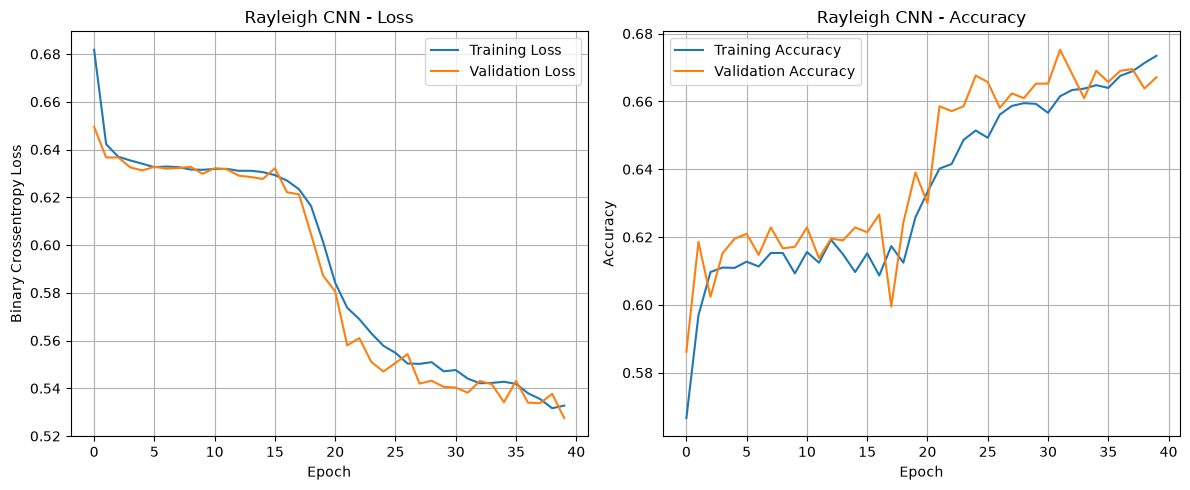

In [29]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Loss curve
plt.subplot(1, 2, 1)
plt.plot(history_rayleigh.history["loss"], label="Training Loss")
plt.plot(history_rayleigh.history["val_loss"], label="Validation Loss")
plt.title("Rayleigh CNN - Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Crossentropy Loss")
plt.legend()
plt.grid(True)

# Accuracy curve
plt.subplot(1, 2, 2)
plt.plot(history_rayleigh.history["accuracy"], label="Training Accuracy")
plt.plot(history_rayleigh.history["val_accuracy"], label="Validation Accuracy")
plt.title("Rayleigh CNN - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [30]:
# Predict on Rayleigh validation data
rayleigh_val_prob = cnn_model_rayleigh.predict(
    X_rayleigh_val_scaled
).ravel()

# Extract H0 probabilities only
rayleigh_val_h0_prob = rayleigh_val_prob[
    y_rayleigh_val == 0
]

# Calibrate threshold for 5% target Pfa
rayleigh_cnn_threshold = np.quantile(
    rayleigh_val_h0_prob,
    0.95,
    method="higher"
)

# Calculate validation predictions
rayleigh_val_pred = (
    rayleigh_val_prob > rayleigh_cnn_threshold
).astype(int)

# Validation confusion matrix
tn, fp, fn, tp = confusion_matrix(
    y_rayleigh_val.astype(int),
    rayleigh_val_pred,
    labels=[0, 1]
).ravel()

rayleigh_val_pfa = fp / (fp + tn)
rayleigh_val_pd = tp / (tp + fn)

print("RAYLEIGH CNN THRESHOLD CALIBRATION")
print("---------------------------------")
print("Threshold:", rayleigh_cnn_threshold)
print("Validation H0 samples:", len(rayleigh_val_h0_prob))
print("Unique H0 probabilities:", len(np.unique(rayleigh_val_h0_prob)))
print("Validation Pfa:", round(rayleigh_val_pfa, 4))
print("Validation Pd:", round(rayleigh_val_pd, 4))

66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
RAYLEIGH CNN THRESHOLD CALIBRATION
---------------------------------
Threshold: 0.60463464
Validation H0 samples: 1050
Unique H0 probabilities: 765
Validation Pfa: 0.0495
Validation Pd: 0.359


In [31]:
# Predict on Rayleigh test data
rayleigh_adapted_test_prob = cnn_model_rayleigh.predict(
    X_rayleigh_test_scaled
).ravel()

# Apply calibrated threshold
rayleigh_adapted_test_pred = (
    rayleigh_adapted_test_prob > rayleigh_cnn_threshold
).astype(int)

# Confusion matrix
tn, fp, fn, tp = confusion_matrix(
    y_rayleigh_test.astype(int),
    rayleigh_adapted_test_pred,
    labels=[0, 1]
).ravel()

# Calculate metrics
rayleigh_adapted_accuracy = accuracy_score(
    y_rayleigh_test,
    rayleigh_adapted_test_pred
)

rayleigh_adapted_pd = tp / (tp + fn)
rayleigh_adapted_pfa = fp / (fp + tn)
rayleigh_adapted_pm = fn / (fn + tp)

rayleigh_adapted_auc = roc_auc_score(
    y_rayleigh_test,
    rayleigh_adapted_test_prob
)

print("RAYLEIGH-TRAINED CNN TEST RESULTS")
print("--------------------------------")
print("Threshold:", round(rayleigh_cnn_threshold, 6))
print("Accuracy:", round(rayleigh_adapted_accuracy, 4))
print("Pd:", round(rayleigh_adapted_pd, 4))
print("Pfa:", round(rayleigh_adapted_pfa, 4))
print("Pm:", round(rayleigh_adapted_pm, 4))
print("ROC-AUC:", round(rayleigh_adapted_auc, 4))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_rayleigh_test.astype(int),
    rayleigh_adapted_test_pred
))

66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
RAYLEIGH-TRAINED CNN TEST RESULTS
--------------------------------
Threshold: 0.604635
Accuracy: 0.65
Pd: 0.3514
Pfa: 0.0514
Pm: 0.6486
ROC-AUC: 0.7614

Confusion Matrix:
[[996  54]
 [681 369]]


In [32]:
# Save trained Rayleigh CNN
cnn_model_rayleigh.save("cnn_model_rayleigh.keras")

# Save normalization parameters and threshold
np.savez(
    "rayleigh_cnn_parameters.npz",
    channel_mean=rayleigh_channel_mean,
    channel_std=rayleigh_channel_std,
    threshold=rayleigh_cnn_threshold
)

# Save test evaluation results
rayleigh_adapted_results = pd.DataFrame([{
    "Model": "Rayleigh-trained 1D-CNN",
    "Training_Channel": "Rayleigh",
    "Testing_Channel": "Rayleigh",
    "Threshold": rayleigh_cnn_threshold,
    "Accuracy": rayleigh_adapted_accuracy,
    "Pd": rayleigh_adapted_pd,
    "Pfa": rayleigh_adapted_pfa,
    "Pm": rayleigh_adapted_pm,
    "ROC_AUC": rayleigh_adapted_auc
}])

rayleigh_adapted_results.to_csv(
    "rayleigh_trained_cnn_results.csv",
    index=False
)

print("Rayleigh CNN model saved.")
print("Normalization parameters saved.")
print("Evaluation results saved.")

Rayleigh CNN model saved.
Normalization parameters saved.
Evaluation results saved.


In [33]:
consolidated_results = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Training_Channel": "AWGN",
        "Testing_Channel": "AWGN",
        "Accuracy": 0.6719,
        "Pd": 0.3838,
        "Pfa": 0.0400,
        "Pm": 0.6162,
        "ROC_AUC": 0.8314
    },
    {
        "Model": "Random Forest",
        "Training_Channel": "AWGN",
        "Testing_Channel": "AWGN",
        "Accuracy": 0.8219,
        "Pd": 0.6990,
        "Pfa": 0.0552,
        "Pm": 0.3010,
        "ROC_AUC": 0.9383
    },
    {
        "Model": "AWGN-trained 1D-CNN",
        "Training_Channel": "AWGN",
        "Testing_Channel": "AWGN",
        "Accuracy": 0.7686,
        "Pd": 0.5733,
        "Pfa": 0.0362,
        "Pm": 0.4267,
        "ROC_AUC": 0.8969
    },
    {
        "Model": "Logistic Regression",
        "Training_Channel": "AWGN",
        "Testing_Channel": "Rayleigh",
        "Accuracy": 0.6281,
        "Pd": 0.2990,
        "Pfa": 0.0429,
        "Pm": 0.7010
    },
    {
        "Model": "Random Forest",
        "Training_Channel": "AWGN",
        "Testing_Channel": "Rayleigh",
        "Accuracy": 0.6833,
        "Pd": 0.4190,
        "Pfa": 0.0524,
        "Pm": 0.5810
    },
    {
        "Model": "AWGN-trained 1D-CNN",
        "Training_Channel": "AWGN",
        "Testing_Channel": "Rayleigh",
        "Accuracy": rayleigh_cnn_accuracy,
        "Pd": rayleigh_cnn_pd,
        "Pfa": rayleigh_cnn_pfa,
        "Pm": rayleigh_cnn_pm,
        "ROC_AUC": rayleigh_cnn_auc
    },
    {
        "Model": "Rayleigh-trained 1D-CNN",
        "Training_Channel": "Rayleigh",
        "Testing_Channel": "Rayleigh",
        "Accuracy": rayleigh_adapted_accuracy,
        "Pd": rayleigh_adapted_pd,
        "Pfa": rayleigh_adapted_pfa,
        "Pm": rayleigh_adapted_pm,
        "ROC_AUC": rayleigh_adapted_auc
    }
])

print(consolidated_results.round(4).to_string(index=False))

consolidated_results.to_csv(
    "consolidated_awgn_rayleigh_comparison.csv",
    index=False
)

print("\nConsolidated comparison saved successfully.")

                  Model Training_Channel Testing_Channel  Accuracy     Pd    Pfa     Pm  ROC_AUC
    Logistic Regression             AWGN            AWGN    0.6719 0.3838 0.0400 0.6162   0.8314
          Random Forest             AWGN            AWGN    0.8219 0.6990 0.0552 0.3010   0.9383
    AWGN-trained 1D-CNN             AWGN            AWGN    0.7686 0.5733 0.0362 0.4267   0.8969
    Logistic Regression             AWGN        Rayleigh    0.6281 0.2990 0.0429 0.7010      NaN
          Random Forest             AWGN        Rayleigh    0.6833 0.4190 0.0524 0.5810      NaN
    AWGN-trained 1D-CNN             AWGN        Rayleigh    0.6343 0.3076 0.0390 0.6924   0.7140
Rayleigh-trained 1D-CNN         Rayleigh        Rayleigh    0.6500 0.3514 0.0514 0.6486   0.7614

Consolidated comparison saved successfully.
